In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import simpson
from scipy.special import jv

pi = np.pi

c:\Users\User\AppData\Local\Programs\Python\Python310\lib\site-packages\matplotlib\cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\User\AppData\Local\Programs\Python\Python310\lib\site-packages\matplotlib\cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


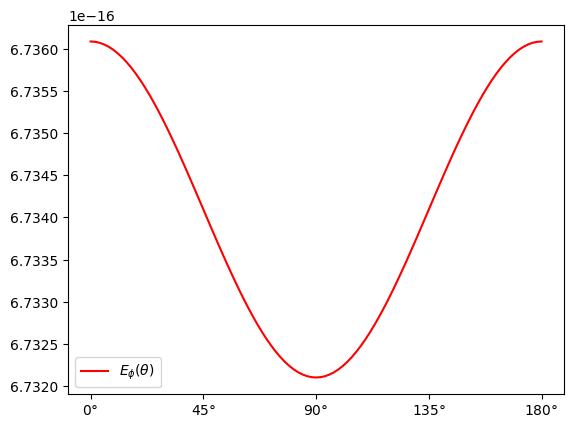

c:\Users\User\AppData\Local\Programs\Python\Python310\lib\site-packages\matplotlib\cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\User\AppData\Local\Programs\Python\Python310\lib\site-packages\matplotlib\cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


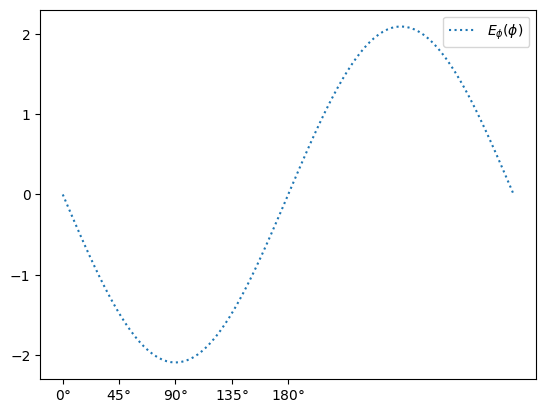

In [4]:
# Ângulos de observação
num = 101  # Número ímpar de pontos

theta = np.linspace(0, np.pi, num)
phi = np.linspace(0, 2*np.pi, num)

# Parâmetros físicos
a = 1.0
lamb = 100.0
k = 2*pi/lamb

rho = np.linspace(0, a, num)
phi_s = np.linspace(0, 2*np.pi, num)

# Formatos dos arrays para broadcasting
RHO = rho[None, :, None]
PHI_OBS = phi[:, None, None]
PHI_SRC = phi_s[None, None, :]

# Integral dupla: resultado para cada par (theta, phi)
I = np.empty((len(theta), len(phi)), dtype=complex)
for i, th in enumerate(theta):
    # Integrando: dimensões (N_phi, N_rho, N_phi_src)
    f = RHO**2 * np.exp(1j * k * RHO * np.sin(th)* np.cos(PHI_OBS - PHI_SRC))
    # Primeira integração: d(phi')
    I_phi = simpson(f, x=phi_s, axis=2)
    # Segunda integração: d(rho')
    I[i, :] = simpson(I_phi, x=rho, axis=1)

# Matriz de ângulos de observação
TH, PH = np.meshgrid(theta, phi, indexing="ij")

# Componentes dos campos
E_theta = np.cos(TH) * np.cos(PH) * I
E_phi = -np.sin(PH) * I

# plt.figure()
# plt.plot(theta,E_theta,label=r'$E_{\theta}(\theta)$',color='red')
# plt.plot(phi,E_theta,ls=':',label=r'$E_{\theta}(\phi)$')
# plt.legend()
# plt.show()

plt.figure()
plt.plot(theta,E_phi[:,int(num/2)],label=r'$E_{\phi}(\theta)$',color='red')
plt.xticks([ 0, np.pi/4, np.pi/2,3*np.pi/4, np.pi],[r"$0°$", r"$45°$", r"$90°$",r"$135°$",r"$180°$"])
plt.legend()
plt.show()

plt.figure()
plt.plot(phi,E_phi[int(num/2),:],ls=':',label=r'$E_{\phi}(\phi)$')
plt.xticks([ 0, np.pi/4, np.pi/2,3*np.pi/4, np.pi],[r"$0°$", r"$45°$", r"$90°$",r"$135°$",r"$180°$"])
plt.legend()
plt.show()